# Estimar el precio por superficie: ¿cuándo ayuda transformar las variables?
### Unidades 2, 3 y 4 · Laboratorio de Datos I · UNTDF

**Parcial E2 · Economía · Resolución individual domiciliaria · Plazo: dos semanas**

Se dispone de transacciones inmobiliarias de un distrito de Nueva Taipéi. El trabajo consiste en explorar los datos y comparar una regresión lineal con alternativas Ridge que representan de otra manera la distancia al transporte y la antigüedad.

**Pregunta central:** ¿las alternativas propuestas, que combinan transformaciones y Ridge, mejoran la estimación del precio por superficie frente a la regresión lineal original, dentro del mercado observado?

Nombre y apellido: Camila Rosales · Carrera:Lic en Economia · Fecha de entrega:

## Guía de trabajo

- Resolver las diez consignas C1–C10 en este archivo, conservando sus títulos. Se pueden agregar celdas de código o texto.
- Usar los datos locales del paquete sin modificarlos. No se requiere descargar otras fuentes ni conocer técnicas de tasación profesional.
- La cátedra entrega la carga, los pliegues y una ayuda para representar variables. **La auditoría, el EDA, los modelos y la interpretación se resuelven en las celdas indicadas.**
- La comparación comprende cinco candidatos fijados y una referencia sencilla. No incorporar otros algoritmos, variables externas o búsquedas adicionales.
- Explorar sólo `desarrollo.csv`. Abrir `prueba.csv` en C8, después de registrar la elección de C7. Las etiquetas de prueba están en el paquete: respetar el orden es parte del procedimiento, no una barrera técnica.
- Entregar el notebook ejecutado desde un kernel limpio, con salidas e interpretaciones, junto a `datasets/`. No se pide un informe separado.

La primera celda de código configura el entorno. Las dependencias probadas se indican en `requirements.txt`. Una ejecución del archivo vacío sólo comprueba el soporte: no constituye una resolución.

**Vocabulario del código.** Variable predictora (*feature*), variable objetivo (*target*), entrenamiento (*training*), validación (*validation*) y prueba (*test*). La validación cruzada (*cross-validation*) utiliza pliegues (*folds*). Una secuencia de transformaciones y modelo (*pipeline*) se ajusta con `fit` y produce predicciones con `predict`. La mediana es el modelo de referencia (*baseline*). `alpha` es un hiperparámetro (*hyperparameter*). Aprender del conjunto reservado durante el ajuste produce filtración de información (*data leakage*).

In [1]:
# === Preparación para Colab: dejar `datasets/` a la vista ===
import os, sys, shutil, hashlib
from pathlib import Path

CARPETA_EN_DRIVE = "E2_valuacion_inmobiliaria"   # ruta dentro de "Mi unidad", ej.: "lab-datos-1/parcial-e2"
ARCHIVOS_ESPERADOS = ("desarrollo.csv", "prueba.csv")
HASHES = {
    "desarrollo.csv": "45105f76927356b5607632aebbaf5b4346565e4191eb69fed32fd7ee7101710c",
    "prueba.csv":     "3310869a25d4b3cb3bf06c0ead84e5b687c3857d16207cd0950abccec1c5379a",
}

def _tiene_datos(base):
    return all((Path(base) / "datasets" / n).exists() for n in ARCHIVOS_ESPERADOS)

def _buscar_en(raiz, profundidad=4):
    """Devuelve la carpeta que contiene desarrollo.csv (dentro o fuera de datasets/)."""
    raiz = Path(raiz)
    for nivel in range(profundidad + 1):
        for hallado in raiz.glob("/".join(["*"] * nivel + [ARCHIVOS_ESPERADOS[0]])):
            return hallado.parent
    return None

if "google.colab" not in sys.modules:
    print("No estás en Colab: abrí el notebook desde la carpeta que contiene datasets/.")
elif _tiene_datos("."):
    print(f"datasets/ ya es visible desde {Path.cwd()}.")
else:
    from google.colab import drive
    drive.mount("/content/drive")
    mi_unidad = Path("/content/drive/MyDrive")
    base = mi_unidad / CARPETA_EN_DRIVE
    if not base.exists():
        base = _buscar_en(mi_unidad)          # plan B: buscar desarrollo.csv en todo Drive
        base = base.parent if base is not None and base.name == "datasets" else base

    if base is None or not base.exists():
        print("No se encontró desarrollo.csv en Drive. Revisá CARPETA_EN_DRIVE.")
    else:
        # Caso: CSV sueltos en la carpeta -> crear datasets/ y copiarlos
        if not _tiene_datos(base):
            (base / "datasets").mkdir(exist_ok=True)
            for n in ARCHIVOS_ESPERADOS:
                if (base / n).exists():
                    shutil.copy2(base / n, base / "datasets" / n)
        if _tiene_datos(base):
            os.chdir(base)
            print(f"Listo. Carpeta de trabajo: {Path.cwd()}")
        else:
            print("Faltan archivos en", base)

# Verificación de integridad (los CSV no deben haberse modificado)
if _tiene_datos("."):
    for n, ok in HASHES.items():
        h = hashlib.sha256(Path("datasets", n).read_bytes()).hexdigest()
        print(f"{n}: {'OK' if h == ok else '¡DISTINTO! volver a subir el original'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Listo. Carpeta de trabajo: /content/drive/MyDrive/E2_valuacion_inmobiliaria
desarrollo.csv: OK
prueba.csv: OK


In [2]:
# === Setup de la cátedra — Laboratorio de Datos I (UNTDF) ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from importlib.metadata import version

SEED = 42
rng = np.random.default_rng(SEED)

# Paleta de la cátedra (fondo claro) — usar por semántica, no por gusto
AZUL   = "#4A7A9B"  # serie base
CIAN   = "#5AA9D6"  # serie secundaria / estructura
DORADO = "#D8A24A"  # transición
AMBAR  = "#E89340"  # único acento: lo que sostiene la conclusión
GRIS   = "#B9C4CE"  # contexto / referencia
TINTA  = "#0E1620"  # texto, ejes y bordes
PROGRESION = [AZUL, CIAN, DORADO, AMBAR]

plt.rcParams.update({
    "figure.figsize": (11.5, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRIS, "grid.alpha": 0.35,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "text.color": TINTA, "axes.labelcolor": TINTA, "axes.edgecolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[AZUL, AMBAR, CIAN, DORADO, GRIS]),
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

**Interpretación.** El entorno y la paleta quedan disponibles. Todas las importaciones se concentran arriba; si se necesita una herramienta adicional, incorporarla a esa celda.

# 1. Comprender qué precio se está estimando
## 1.1 Contexto, unidades y lecturas

En una transacción, el **precio por superficie** permite comparar inmuebles de tamaños distintos. Aquí la variable objetivo no es el precio total de la vivienda: se expresa en **10.000 dólares taiwaneses (TWD) por ping**. Un ping equivale aproximadamente a 3,3 m² según la documentación de la fuente. No convertir monedas ni superficies durante el análisis.

Ejemplo exclusivamente ilustrativo: un valor objetivo de 40 representa 400.000 TWD por ping. Un error de 5 unidades representa 50.000 TWD por ping; no es un error del 5 %. Para estimar el precio total sería necesaria la superficie del inmueble, que no se incluye.

MRT es el transporte ferroviario metropolitano. La distancia a su estación más cercana aproxima una dimensión de accesibilidad. La antigüedad se mide en años; los comercios cercanos cuentan establecimientos del entorno caminable. Las coordenadas describen ubicación; no indican por sí solas la calidad del inmueble.

Se plantea una **estimación retrospectiva** de transacciones del mercado observado, usando sus seis características. No se evalúa el precio de otra ciudad ni un período futuro. La fecha decimal se conserva como valor numérico según la fuente, sin reconstruir meses a partir de sus redondeos.

Lectura de apoyo opcional: [ficha y variables de UCI Real Estate Valuation](https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set), especialmente descripción, variables y unidades. La explicación anterior permite resolver el contexto sin leer el artículo científico. Dedicación contextual prevista: hasta dos horas; registrar dudas que la fuente no permita resolver.

## 1.2 Diccionario incorporado

| Columna | Significado / unidad | Uso |
|---|---|---|
| `id_operacion` | Número de fila original | Identificación; nunca predictor |
| `fecha_decimal` | Fecha de transacción en la codificación numérica original | Predictor |
| `antiguedad_anios` | Antigüedad, años; cero admite un inmueble nuevo | Predictor |
| `distancia_mrt_m` | Distancia a la estación MRT más cercana, metros | Predictor |
| `comercios_cercanos` | Cantidad de comercios del entorno caminable | Predictor |
| `latitud`, `longitud` | Coordenadas, grados | Predictores |
| `precio_10mil_twd_ping` | Precio por superficie, en 10.000 TWD/ping | Objetivo |
| `grupo_ubicacion` | Código creado por la cátedra para coordenadas exactamente coincidentes | Sólo separación |
| `fold_validacion` | Pliegue (fold) de validación; columna presente sólo en desarrollo | Sólo separación; no predictor |

La cátedra renombró columnas y agregó campos de separación. No completó valores faltantes ni suavizó extremos. Las coordenadas coincidentes se mantienen juntas, pero **no identifican con certeza un edificio** ni eliminan toda dependencia entre lugares próximos.

## 1.3 Consigna C1 — Formular el problema

Completar la tabla con frases propias. Explicar además por qué predecir precio por superficie y predecir precio total son tareas diferentes. No formular una recomendación de compra: el objetivo es evaluar una estimación estadística.

| Elemento | Respuesta |
|---|---|
| Unidad de observación | Cada fila del dataset: una transacción inmobiliaria (una compraventa) de un distrito de Nueva Taipéi. |
| Variable objetivo y unidad | El precio por superficie (`precio_10mil_twd_ping`), medido en 10.000 dólares taiwaneses (TWD) por ping. Un ping son más o menos 3,3 m². |
| Información disponible para estimar | Seis datos de cada transacción: fecha, antigüedad en años, distancia a la estación MRT más cercana en metros, cantidad de comercios cerca, latitud y longitud. El ID y las columnas de grupo y pliegue sirven solo para identificar o separar los datos, no para predecir. |
| Decisión que puede apoyar y límite principal | Puede servir como una referencia estadística para tener una idea del precio por superficie de inmuebles parecidos dentro de este mercado. El límite principal es que el modelo se arma con 414 transacciones de un solo distrito y sin datos propios del inmueble (superficie, estado, calidad), así que no sirve para otra ciudad ni para otra época, y no es una recomendación de compra. |

**Diferencia entre precio por superficie y precio total:** El precio por superficie dice cuánto vale cada ping, mientras que el precio total es lo que cuesta el inmueble entero, o sea ese valor multiplicado por la cantidad de ping que tiene. Son tareas distintas porque para predecir el total haría falta saber la superficie, y este dataset no la trae. Dos departamentos pueden tener el mismo precio por ping y costar muy distinto si uno es más grande que el otro. Además, el error del modelo está en unidades de 10.000 TWD por ping: equivocarse por 5 significa 50.000 TWD por ping, no un 5 % del precio, y tampoco es un error en el valor total de la vivienda.

# 2. Separar comparación y evaluación final
## 2.1 El recorrido de los datos

| Momento | Datos | Qué está permitido |
|---|---|---|
| C3–C5: auditoría, EDA y preparación | Desarrollo | Comprender y preparar el problema dentro del menú fijado |
| C6: validación cruzada | Cinco pliegues de desarrollo | Entrenar con cuatro, validar con uno; repetir cinco veces |
| C7: selección | Resultados de los cinco pliegues | Elegir y registrar una configuración |
| C8–C9: prueba final | Prueba reservada | Evaluar la configuración elegida y analizar errores |

En cada pliegue se crea un **modelo nuevo** y el escalador se ajusta exclusivamente con sus cuatro partes de entrenamiento. La representación logarítmica y el cuadrado son operaciones deterministas; el promedio y el desvío del escalador sí se aprenden de los datos.

La separación inicial reservó aproximadamente el 20 % de las ubicaciones; el porcentaje de filas puede diferir porque los grupos tienen tamaños distintos. La cátedra entrega las asignaciones, que no se deben modificar. Después de elegir, se vuelve a ajustar el candidato con todo desarrollo y se abre prueba una sola vez.

El EDA de desarrollo y la selección utilizan datos comunes. Por ello, el mejor MAE de validación es una señal para elegir, no una certificación independiente de rendimiento; la prueba final cumple esa función dentro de los límites de la muestra.

## 2.2 Cargar desarrollo y reconocer los pliegues

El soporte siguiente lee exclusivamente el archivo de desarrollo y entrega `pliegues`, una lista de cinco pares de índices posicionales `(entrenamiento, validacion)`. Se usan con `.iloc`. También verifica que cada ubicación permanezca en un único pliegue; no realiza el análisis de calidad solicitado en C3.

In [3]:
RUTA_DATOS = Path("datasets")
OBJETIVO = "precio_10mil_twd_ping"
PREDICTORES = ["fecha_decimal", "antiguedad_anios", "distancia_mrt_m",
               "comercios_cercanos", "latitud", "longitud"]

if not (RUTA_DATOS / "desarrollo.csv").is_file():
    raise FileNotFoundError("Abrir el notebook dentro de la carpeta que contiene datasets/.")
desarrollo = pd.read_csv(RUTA_DATOS / "desarrollo.csv")
assert desarrollo.groupby("grupo_ubicacion")["fold_validacion"].nunique().max() == 1
ids_fold = sorted(desarrollo["fold_validacion"].unique())
assert len(ids_fold) == 5
pliegues = []
for fold in ids_fold:
    idx_ent = np.flatnonzero(desarrollo["fold_validacion"].to_numpy() != fold)
    idx_val = np.flatnonzero(desarrollo["fold_validacion"].to_numpy() == fold)
    assert set(desarrollo.iloc[idx_ent]["grupo_ubicacion"]).isdisjoint(
        set(desarrollo.iloc[idx_val]["grupo_ubicacion"]))
    pliegues.append((idx_ent, idx_val))
display(pd.DataFrame({"pliegue": ids_fold,
                      "n_entrenamiento": [len(e) for e, v in pliegues],
                      "n_validacion": [len(v) for e, v in pliegues]}))

,pliegue,n_entrenamiento,n_validacion
0,1,275,69
1,2,275,69
2,3,275,69
3,4,275,69
4,5,276,68


**Interpretación.** La tabla muestra cuántas filas se usan para ajustar y validar en cada vuelta. Cada fila de desarrollo participa una vez en validación. Esta tabla no contiene resultados de modelos ni información de prueba.

## 2.3 Consigna C2 — Justificar exclusiones y separación

1. Identificar los cuatro campos que no pueden entrar en `X` y explicar el motivo de cada exclusión.
2. Explicar, en hasta cinco líneas, qué problema evita agrupar coordenadas coincidentes y qué dependencia espacial puede persistir.
3. Explicar por qué escalar todo desarrollo antes de la validación cruzada no respeta este protocolo.

No se pide implementar un algoritmo para crear los pliegues.

**1. Los cuatro campos que no pueden entrar en `X`:**

- `precio_10mil_twd_ping`: es lo que queremos predecir. Si lo usáramos como predictor, el modelo ya tendría la respuesta y daría error cero sin aprender nada.
- `id_operacion`: es solo el número de fila del archivo original. No dice nada sobre la propiedad, así que no aporta información real y podría meter ruido.
- `grupo_ubicacion`: es un código que armó la cátedra para agrupar las coordenadas que son iguales. Sirve para separar los datos, no describe al inmueble.
- `fold_validacion`: dice en qué pliegue cae cada fila. Es solo para dividir los datos en la validación, y para una transacción nueva ni siquiera existiría.

**2. Agrupar coordenadas coincidentes:**

Si dos transacciones de exactamente el mismo lugar quedaran una en entrenamiento y otra en validación, el modelo "se acordaría" de ese lugar y acertaría casi de memoria, y el resultado de la validación saldría mejor de lo que es en realidad. Al dejar cada ubicación en un solo pliegue se evita eso. Lo que sigue pudiendo pasar es que



# 3. Auditar antes de transformar
## 3.1 Consigna C3 — Registrar la calidad de desarrollo

Informar tipos, nulos, no finitos y unicidad de `id_operacion`; contar duplicados exactos considerando los seis predictores y el objetivo, sin usar el ID. Distinguirlos de ubicaciones repetidas. Verificar objetivo positivo, antigüedad y distancia no negativas, comercios enteros no negativos y coordenadas válidas (latitud entre −90 y 90, longitud entre −180 y 180).

Presentar una tabla de controles y cantidades. Los controles que den cero también deben informarse. Un registro idéntico sin ID puede corresponder a otra transacción: no eliminarlo automáticamente. No consultar prueba.

In [4]:
# C3 · Auditoría de calidad de desarrollo (sin tocar prueba)
columnas_modelo = PREDICTORES + [OBJETIVO]          # 6 predictores + objetivo, sin ID
num = desarrollo[columnas_modelo]

# 1) Tipos de datos
print("Tipos de datos:")
display(desarrollo.dtypes.to_frame("tipo"))
print("Forma de la tabla (filas, columnas):", desarrollo.shape)

# 2) Duplicados exactos (sin ID) vs. ubicaciones repetidas
dup_exactos = desarrollo.duplicated(subset=columnas_modelo).sum()          # filas "de más"
filas_en_ubic_rep = desarrollo.duplicated(subset=["latitud", "longitud"], keep=False).sum()
ubic_extra = desarrollo.duplicated(subset=["latitud", "longitud"]).sum()

# 3) Tabla de controles: cada control con la cantidad de filas que lo incumplen
c = desarrollo["comercios_cercanos"]
controles = pd.DataFrame([
    ("Valores nulos (todas las columnas)",               int(desarrollo.isna().sum().sum())),
    ("Valores no finitos (inf / NaN) en numéricas",      int((~np.isfinite(num.to_numpy(dtype=float))).sum())),
    ("IDs repetidos (`id_operacion`)",                   int(desarrollo["id_operacion"].duplicated().sum())),
    ("Duplicados exactos (6 predictores + objetivo)",    int(dup_exactos)),
    ("Objetivo no positivo (precio <= 0)",               int((desarrollo[OBJETIVO] <= 0).sum())),
    ("Antigüedad negativa",                              int((desarrollo["antiguedad_anios"] < 0).sum())),
    ("Distancia al MRT negativa",                        int((desarrollo["distancia_mrt_m"] < 0).sum())),
    ("Comercios no enteros",                             int((c != np.floor(c)).sum())),
    ("Comercios negativos",                              int((c < 0).sum())),
    ("Latitud fuera de [-90, 90]",                       int((~desarrollo["latitud"].between(-90, 90)).sum())),
    ("Longitud fuera de [-180, 180]",                    int((~desarrollo["longitud"].between(-180, 180)).sum())),
], columns=["Control", "Filas que lo incumplen"])
display(controles)

# 4) Información que NO es un problema, pero conviene registrar
informativos = pd.DataFrame([
    ("Filas totales",                                         len(desarrollo)),
    ("Ubicaciones distintas (`grupo_ubicacion`)",             desarrollo["grupo_ubicacion"].nunique()),
    ("Filas que comparten coordenadas con otra",              int(filas_en_ubic_rep)),
    ("Filas 'extra' por ubicación repetida",                  int(ubic_extra)),
    ("Inmuebles con antigüedad = 0 (nuevos)",                 int((desarrollo["antiguedad_anios"] == 0).sum())),
], columns=["Dato", "Cantidad"])
display(informativos)

Tipos de datos:


,tipo
id_operacion,int64
fecha_decimal,float64
antiguedad_anios,float64
distancia_mrt_m,float64
comercios_cercanos,int64
latitud,float64
longitud,float64
precio_10mil_twd_ping,float64
grupo_ubicacion,int64
fold_validacion,int64


Forma de la tabla (filas, columnas): (344, 10)


,Control,Filas que lo incumplen
0,Valores nulos (todas las columnas),0
1,Valores no finitos (inf / NaN) en numéricas,0
2,IDs repetidos (`id_operacion`),0
3,Duplicados exactos (6 predictores + objetivo),0
4,Objetivo no positivo (precio <= 0),0
5,Antigüedad negativa,0
6,Distancia al MRT negativa,0
7,Comercios no enteros,0
8,Comercios negativos,0
9,"Latitud fuera de [-90, 90]",0


,Dato,Cantidad
0,Filas totales,344
1,Ubicaciones distintas (`grupo_ubicacion`),207
2,Filas que comparten coordenadas con otra,196
3,Filas 'extra' por ubicación repetida,137
4,Inmuebles con antigüedad = 0 (nuevos),17


**Interpretación.** Los datos de desarrollo están limpios: no hay nulos, valores no finitos, IDs repetidos ni duplicados exactos, y todos los controles de rango dieron cero. Lo que sí hay son ubicaciones repetidas: 344 filas pero solo 207 ubicaciones distintas. Eso no es un duplicado, porque el resto de los valores cambia, y es justo la razón por la que la cátedra agrupó por ubicación. También hay 17 inmuebles con antigüedad cero, que corresponden a inmuebles nuevos y no son un error. Por eso no hace falta eliminar ni corregir ninguna observación.

# 4. Explorar para formular una expectativa
## 4.1 Consigna C4 — Tres preguntas, tres gráficos

Con desarrollo:

1. **¿Qué dispersión tiene el precio?** Tabla de `n`, media, mediana, desvío muestral e IQR para objetivo, antigüedad y distancia; histograma del objetivo.
2. **¿La relación entre distancia y precio parece uniforme?** Dispersión de distancia frente al objetivo, con eje horizontal lineal. Describir curvatura y concentración de observaciones, sin atribuir causalidad.
3. **¿Cómo se relacionan antigüedad y precio?** Elegir dispersión o boxplots por intervalos `[0,10)`, `[10,20)`, `[20,30)` y `30 o más` años; justificar la elección e indicar soporte si se agrupa.

Usar tres figuras, ejes con unidades e interpretación después de cada una. Cerrar con una expectativa sobre cuál transformación podría resultar útil; todavía no afirmar que mejora la predicción.

,n,Media,Mediana,Desvío (ddof=1),IQR
Variable,,,,,
Precio (10.000 TWD/ping),344,38.51,39.20,13.36,18.37
Antigüedad (años),344,17.12,15.65,11.28,18.40
Distancia al MRT (m),344,1038.14,492.23,1210.68,1119.21


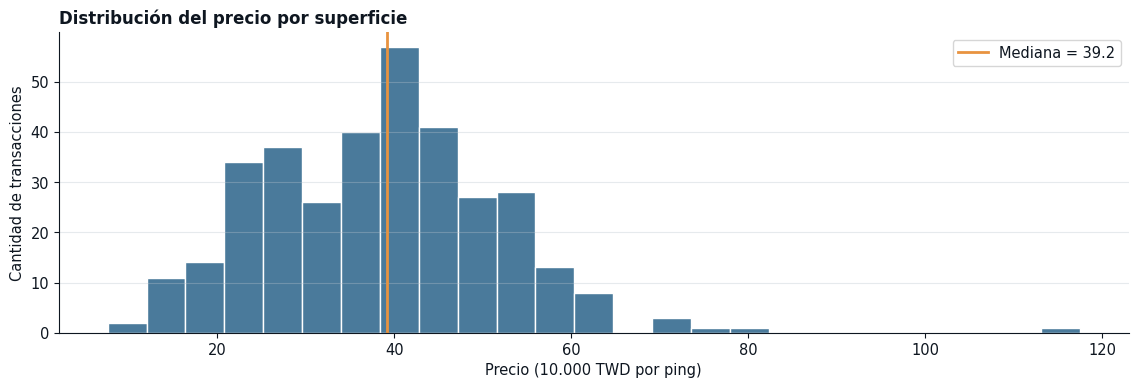

In [5]:
# C4 · Pregunta 1: dispersión del precio (tabla + histograma)
variables = {
    "Precio (10.000 TWD/ping)": OBJETIVO,
    "Antigüedad (años)": "antiguedad_anios",
    "Distancia al MRT (m)": "distancia_mrt_m",
}
filas = []
for nombre, col in variables.items():
    s = desarrollo[col]
    filas.append({
        "Variable": nombre,
        "n": int(s.count()),
        "Media": s.mean(),
        "Mediana": s.median(),
        "Desvío (ddof=1)": s.std(ddof=1),          # desvío muestral
        "IQR": s.quantile(0.75) - s.quantile(0.25) # rango intercuartílico
    })
tabla_desc = pd.DataFrame(filas).set_index("Variable").round(2)
display(tabla_desc)

fig, ax = plt.subplots()
ax.hist(desarrollo[OBJETIVO], bins=25, color=AZUL, edgecolor="white")
ax.axvline(desarrollo[OBJETIVO].median(), color=AMBAR, lw=2,
           label=f"Mediana = {desarrollo[OBJETIVO].median():.1f}")
ax.set_title("Distribución del precio por superficie")
ax.set_xlabel("Precio (10.000 TWD por ping)")
ax.set_ylabel("Cantidad de transacciones")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** El precio medio es 38,5 y la mediana 39,2 (en 10.000 TWD por ping), así que están bastante cerca y el centro de los datos es estable. El desvío es 13,4 y el IQR 18,4: la mayoría de los precios está entre 28 y 47 aproximadamente. El histograma muestra una cola derecha, con unas pocas transacciones muy caras (el máximo es 117,5), que la tabla no deja ver tan bien. Estos valores extremos se conservan, porque la consigna no autoriza a descartarlos. Se nota también que la distancia tiene una media (1.038 m) mucho mayor que su mediana (492 m): la mayoría de los inmuebles está cerca del MRT y unos pocos están muy lejos.

La segunda figura permite examinar si un mismo cambio en metros se asocia con diferencias similares de precio a lo largo del eje.

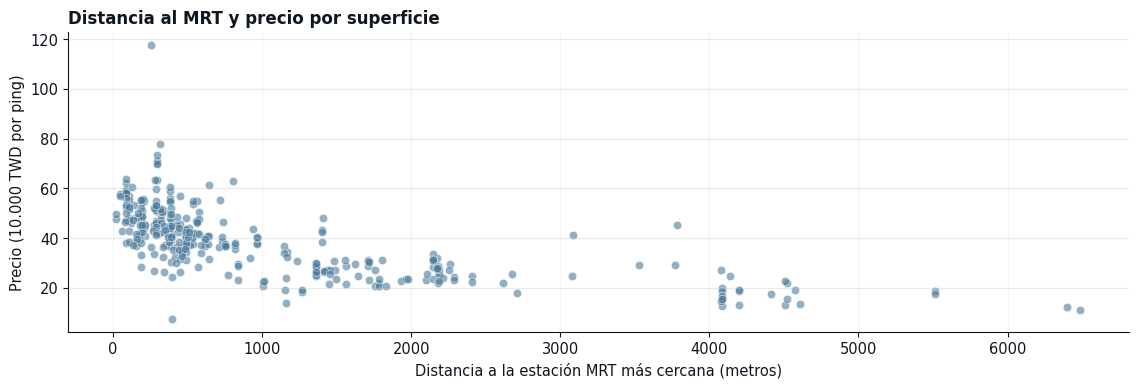

In [6]:
# C4 · Pregunta 2: distancia al MRT vs. precio (eje horizontal lineal)
fig, ax = plt.subplots()
ax.scatter(desarrollo["distancia_mrt_m"], desarrollo[OBJETIVO],
           color=AZUL, alpha=0.6, edgecolor="white", linewidth=0.5)
ax.set_title("Distancia al MRT y precio por superficie")
ax.set_xlabel("Distancia a la estación MRT más cercana (metros)")
ax.set_ylabel("Precio (10.000 TWD por ping)")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretación.** El precio baja a medida que aumenta la distancia, pero no lo hace de forma pareja: la caída es muy fuerte en los primeros cientos de metros y después se aplana, formando una curva y no una recta. Además, la mayoría de las observaciones se amontona cerca del MRT (la mitad está a menos de unos 500 m) y hay pocos puntos a más de 2.000 m. Como el eje es lineal, esa zona cercana se ve apretada. Esto muestra una asociación y no permite decir que la distancia cause el precio: puede haber otras cosas detrás, como la zona o los comercios.

La tercera figura debe mostrar la relación con la antigüedad, aclarando qué se gana o pierde al agrupar observaciones.

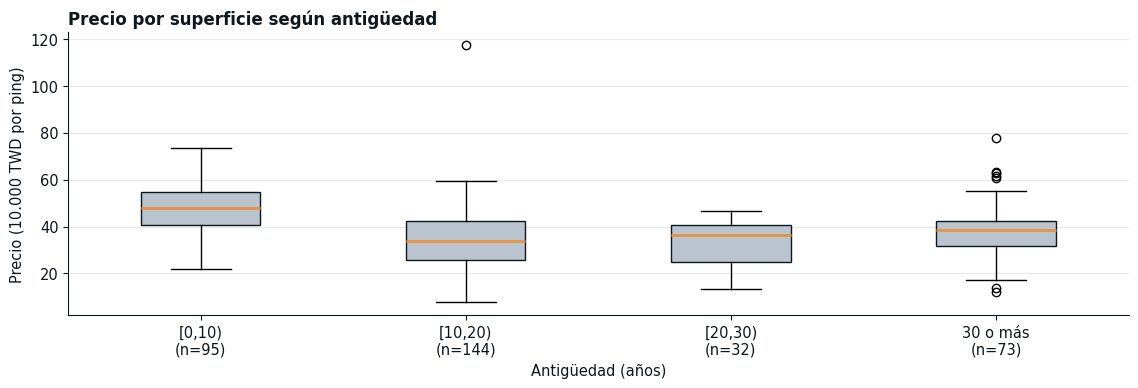

,n
antiguedad_anios,
"[0,10)",95
"[10,20)",144
"[20,30)",32
30 o más,73


In [7]:
# C4 · Pregunta 3: antigüedad vs. precio (boxplots por intervalos)
cortes = [0, 10, 20, 30, np.inf]
etiquetas = ["[0,10)", "[10,20)", "[20,30)", "30 o más"]
intervalo = pd.cut(desarrollo["antiguedad_anios"], bins=cortes,
                   labels=etiquetas, right=False)   # right=False: incluye el límite izquierdo
grupos = [desarrollo.loc[intervalo == e, OBJETIVO] for e in etiquetas]
soporte = intervalo.value_counts().reindex(etiquetas)  # cantidad de casos por intervalo

fig, ax = plt.subplots()
ax.boxplot(grupos,
           tick_labels=[f"{e}\n(n={soporte[e]})" for e in etiquetas],
           patch_artist=True,
           boxprops=dict(facecolor=GRIS, edgecolor=TINTA),
           medianprops=dict(color=AMBAR, lw=2))
ax.set_title("Precio por superficie según antigüedad")
ax.set_xlabel("Antigüedad (años)")
ax.set_ylabel("Precio (10.000 TWD por ping)")
plt.tight_layout()
plt.show()

display(soporte.to_frame("n"))

**Interpretación.** Elegí boxplots por intervalos porque la antigüedad toma valores repetidos (por ejemplo, 17 inmuebles nuevos con 0 años) y los boxplots permiten comparar la mediana y la dispersión de cada grupo con más claridad que una nube de puntos. Se ve que los inmuebles de menos de 10 años son los más caros (mediana cerca de 48), el precio cae en el intervalo de 10 a 20 años (cerca de 34) y vuelve a subir un poco en los más viejos (alrededor de 37 a 38). O sea que la relación no es una recta: tiene forma de curva. Al agrupar se gana claridad pero se pierde el detalle dentro de cada intervalo, y los grupos tienen soporte desigual: 95, 144, 32 y 73 casos, con apenas 32 en el de 20 a 30 años, por lo que esa mediana es menos confiable.

# 5. Preparar sin aprender de la validación
## 5.1 Representaciones permitidas y soporte

Se mantienen las seis variables del contrato. Las alternativas son:

| Nombre | Operación |
|---|---|
| `original` | Las seis variables originales |
| `logdist` | Reemplazar distancia por `log1p(distancia)`; mantener las otras cinco |
| `logdist_edad2` | Igual a `logdist` y agregar antigüedad al cuadrado |

El logaritmo es natural. La convención usa la distancia expresada en metros; no cambiar la unidad antes de transformar. El cuadrado usa la antigüedad en años. La función siguiente aplica esas operaciones fila por fila y **no aprende parámetros**.

In [8]:
def representar(tabla, modo):
    """Soporte determinista: no ajusta escalas ni utiliza la variable objetivo."""
    if modo not in {"original", "logdist", "logdist_edad2"}:
        raise ValueError("Representación no autorizada")
    x = tabla[PREDICTORES].copy()
    if modo != "original":
        x["distancia_mrt_m"] = np.log1p(x["distancia_mrt_m"])
        x = x.rename(columns={"distancia_mrt_m": "log_distancia_m"})
    if modo == "logdist_edad2":
        x["antiguedad_cuadrado"] = x["antiguedad_anios"] ** 2
    return x

**Interpretación.** La función devuelve las columnas de una representación. El escalado y el modelo se construyen en C5–C6. Es válido calcular estas transformaciones deterministas para una tabla completa; no es válido ajustar allí el escalador antes de separar los pliegues.

## 5.2 Consigna C5 — Construir una preparación reproducible

1. Registrar en una tabla los hallazgos de C3, el tratamiento y las filas afectadas. Conservar todas las observaciones y los extremos: no hay autorización para descartarlos por su precio ni para reemplazarlos automáticamente. Proponer en texto qué evidencia adicional justificaría corregir un dato.
2. Preparar las tres matrices con `representar`, mostrando el nombre de cada representación y los nombres y la cantidad de sus columnas; excluir el objetivo y los metadatos.
3. Construir una función o estructura reutilizable que combine `StandardScaler` y un estimador. El escalador deberá ajustarse al llamar a `fit` sobre cada entrenamiento, no antes. Se puede usar `Pipeline`, como en los notebooks de U3.
4. Explicar por qué el escalado es relevante para Ridge y por qué no se escala aquí la variable objetivo.

No se evalúa la programación de `representar`; sí el uso correcto del escalador.

In [9]:
# C5 · Preparación reproducible

# --- 1) Tabla de hallazgos, tratamiento y filas afectadas ---
q1, q3 = desarrollo[OBJETIVO].quantile([0.25, 0.75])
limite_sup = q3 + 1.5 * (q3 - q1)                      # criterio de Tukey, solo para describir
n_extremos = int((desarrollo[OBJETIVO] > limite_sup).sum())
mask_ubic = desarrollo.duplicated(["latitud", "longitud"], keep=False)

hallazgos = pd.DataFrame([
    ("Nulos y valores no finitos",        0,  "Ninguno: no hay nada que corregir"),
    ("IDs repetidos",                     0,  "Ninguno"),
    ("Duplicados exactos (sin ID)",       0,  "Ninguno"),
    ("Ubicaciones repetidas",             int(mask_ubic.sum()), "Se conservan; la cátedra ya las agrupó en un mismo pliegue"),
    ("Antigüedad = 0 (inmuebles nuevos)", int((desarrollo["antiguedad_anios"] == 0).sum()), "Se conservan: es un valor válido"),
    ("Precios extremos (> Q3 + 1,5·IQR)", n_extremos, "Se conservan: no hay autorización para descartarlos"),
], columns=["Hallazgo", "Filas afectadas", "Tratamiento"])
display(hallazgos)

# --- 2) Las tres matrices de predictores (sin objetivo ni metadatos) ---
representaciones = ["original", "logdist", "logdist_edad2"]
matrices = {m: representar(desarrollo, m) for m in representaciones}
y = desarrollo[OBJETIVO]                                # objetivo, sin escalar

resumen = pd.DataFrame({
    "Representación": representaciones,
    "N.º de columnas": [matrices[m].shape[1] for m in representaciones],
    "Columnas": [", ".join(matrices[m].columns) for m in representaciones],
})
display(resumen)

# --- 3) Pipeline reutilizable: el escalador se ajusta dentro de cada fit ---
def crear_modelo(estimador):
    """Devuelve un pipeline NUEVO: StandardScaler + estimador."""
    return Pipeline([("escalador", StandardScaler()),
                     ("modelo", estimador)])

# Ejemplo (solo para ver su estructura; en C6 se crea uno nuevo por pliegue)
print(crear_modelo(Ridge(alpha=10.0)))

,Hallazgo,Filas afectadas,Tratamiento
0,Nulos y valores no finitos,0,Ninguno: no hay nada que corregir
1,IDs repetidos,0,Ninguno
2,Duplicados exactos (sin ID),0,Ninguno
3,Ubicaciones repetidas,196,Se conservan; la cátedra ya las agrupó en un m...
4,Antigüedad = 0 (inmuebles nuevos),17,Se conservan: es un valor válido
5,"Precios extremos (> Q3 + 1,5·IQR)",2,Se conservan: no hay autorización para descart...


,Representación,N.º de columnas,Columnas
0,original,6,"fecha_decimal, antiguedad_anios, distancia_mrt..."
1,logdist,6,"fecha_decimal, antiguedad_anios, log_distancia..."
2,logdist_edad2,7,"fecha_decimal, antiguedad_anios, log_distancia..."


Pipeline(steps=[('escalador', StandardScaler()), ('modelo', Ridge(alpha=10.0))])


**Evidencia para corregir un dato:** No corregí ni eliminé ninguna observación. Para modificar un dato haría falta evidencia externa, como el registro original de la transacción o una contradicción clara (por ejemplo, una coordenada fuera del distrito). Un precio alto por sí solo no alcanza, porque puede ser una operación real.

**Escalado y Ridge:** Ridge penaliza los coeficientes grandes. Si las variables tienen escalas muy distintas (la distancia llega a miles de metros y los comercios van de 0 a 10), la penalización no se reparte parejo. Al estandarizar, todas quedan en la misma escala y Ridge las trata de forma comparable.

**Por qué no se escala el objetivo:** Porque no es un predictor y no necesita penalización. Además, si se escalara, el error dejaría de estar en 10.000 TWD por ping y perdería su interpretación directa.

**Interpretación:** Las tres representaciones tienen las columnas esperadas (6, 6 y 7), sin el objetivo ni los metadatos. El pipeline junta el escalador y el modelo, así que en cada `fit` el escalador aprende solo con ese entrenamiento y no hay filtración.

# 6. Comparar métodos mediante validación cruzada
## 6.1 Métrica, referencia y candidatos

El **error absoluto medio (mean absolute error, MAE)** se define como

$$
\operatorname{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.
$$

Aquí $n$ es el número de transacciones evaluadas, $y_i$ el precio observado y $\hat y_i$ su predicción. MAE se expresa en 10.000 TWD/ping y menor es mejor. Se promedian los cinco MAE de validación con igual peso; se informa además su desvío muestral (`ddof=1`). Esa dispersión no es un intervalo de confianza.

**Referencia:** predecir la mediana de precios del entrenamiento de cada pliegue, sin usar sus variables. **Desafío:** intentar reducir su MAE y explicar qué aporta la mejor alternativa frente a la regresión lineal. Una mejora ausente o pequeña es un resultado válido si el procedimiento y la interpretación son correctos.

**Resultado público de referencia del paquete:** MAE medio de la mediana en validación ≈ **10,5369**, con desvío muestral ≈ **1,6997**. Reproducirlo con los pliegues provistos antes de comparar los candidatos. No es una marca de prueba final ni una condición de aprobación.

| ID | Método | Representación | Parámetro |
|---|---|---|---|
| `lineal` | Regresión lineal con intercepto | `original` | Sin regularización |
| `ridge_log_01` | Ridge con intercepto | `logdist` | `alpha=0.1` |
| `ridge_log_10` | Ridge con intercepto | `logdist` | `alpha=10` |
| `ridge_curva_01` | Ridge con intercepto | `logdist_edad2` | `alpha=0.1` |
| `ridge_curva_10` | Ridge con intercepto | `logdist_edad2` | `alpha=10` |

Se comparan esas cinco configuraciones y la mediana. La comparación conjunta cambia representación y regularización: no atribuir toda mejora exclusivamente a Ridge. La comparación entre las dos representaciones Ridge al mismo `alpha` aporta evidencia sobre el término cuadrático.

## 6.2 Consigna C6 — Ejecutar y resumir la comparación

Para cada candidato y cada par de `pliegues`: crear un pipeline nuevo, ajustar con entrenamiento y obtener predicciones en entrenamiento y validación. Ajustar también la referencia con la mediana de ese entrenamiento. No reutilizar un modelo ya ajustado entre pliegues.

Entregar:

- tabla de parámetros efectivos (representación, escalado, intercepto y `alpha` cuando corresponda) de cada candidato y una explicación breve de `alpha`;
- tabla de seis filas (cinco candidatos y mediana) con MAE medio de entrenamiento, MAE medio de validación, desvío muestral del MAE de validación y diferencia validación–entrenamiento;
- los cinco errores de validación por candidato para poder revisar el promedio;
- interpretación de hasta ocho líneas: mejora frente a referencia, diferencia entre representaciones y brecha de entrenamiento/validación.

Se pueden usar `clone`, un bucle explícito o funciones de scikit-learn. Si se usa `cross_validate`, sus campos `test_score` se refieren al pliegue de validación, **no al archivo de prueba final**.

In [10]:
# C6 · Validación cruzada: 5 candidatos + mediana de referencia

# --- 1) Candidatos: (representación, estimador) ---
candidatos = {
    "lineal":         ("original",      LinearRegression()),
    "ridge_log_01":   ("logdist",       Ridge(alpha=0.1)),
    "ridge_log_10":   ("logdist",       Ridge(alpha=10)),
    "ridge_curva_01": ("logdist_edad2", Ridge(alpha=0.1)),
    "ridge_curva_10": ("logdist_edad2", Ridge(alpha=10)),
}

# Tabla de parámetros efectivos
parametros = pd.DataFrame([
    {"ID": nombre,
     "Representación": rep,
     "Escalado": "StandardScaler (ajustado en cada entrenamiento)",
     "Intercepto": "Sí",
     "alpha": getattr(est, "alpha", "—")}      # la lineal no tiene alpha
    for nombre, (rep, est) in candidatos.items()
]).set_index("ID")
display(parametros)

# --- 2) Bucle de validación cruzada ---
mae_ent, mae_val = {}, {}
for nombre, (rep, est) in candidatos.items():
    X = matrices[rep]
    errores_ent, errores_val = [], []
    for idx_ent, idx_val in pliegues:
        modelo = crear_modelo(clone(est))                  # modelo NUEVO en cada pliegue
        modelo.fit(X.iloc[idx_ent], y.iloc[idx_ent])       # se ajusta solo con entrenamiento
        errores_ent.append(mean_absolute_error(y.iloc[idx_ent], modelo.predict(X.iloc[idx_ent])))
        errores_val.append(mean_absolute_error(y.iloc[idx_val], modelo.predict(X.iloc[idx_val])))
    mae_ent[nombre], mae_val[nombre] = errores_ent, errores_val

# Referencia: mediana del precio de entrenamiento de cada pliegue
errores_ent, errores_val = [], []
for idx_ent, idx_val in pliegues:
    ref = DummyRegressor(strategy="median")
    ref.fit(matrices["original"].iloc[idx_ent], y.iloc[idx_ent])
    errores_ent.append(mean_absolute_error(y.iloc[idx_ent], ref.predict(matrices["original"].iloc[idx_ent])))
    errores_val.append(mean_absolute_error(y.iloc[idx_val], ref.predict(matrices["original"].iloc[idx_val])))
mae_ent["mediana"], mae_val["mediana"] = errores_ent, errores_val

# --- 3) Tabla resumen (6 filas) ---
resumen_cv = pd.DataFrame({
    nombre: {
        "MAE entrenamiento (media)": np.mean(mae_ent[nombre]),
        "MAE validación (media)":    np.mean(mae_val[nombre]),
        "Desvío MAE validación":     np.std(mae_val[nombre], ddof=1),
        "Validación − entrenamiento": np.mean(mae_val[nombre]) - np.mean(mae_ent[nombre]),
    } for nombre in mae_val
}).T.round(4)
display(resumen_cv)

# --- 4) Los cinco errores de validación de cada candidato ---
errores_por_pliegue = pd.DataFrame(mae_val, index=[f"Pliegue {f}" for f in ids_fold]).T.round(4)
display(errores_por_pliegue)

# Control con el valor público de la cátedra (mediana): ≈ 10,5369 y ≈ 1,6997
print("Control mediana → media:", round(np.mean(mae_val["mediana"]), 4),
      "| desvío:", round(np.std(mae_val["mediana"], ddof=1), 4))

,Representación,Escalado,Intercepto,alpha
ID,,,,
lineal,original,StandardScaler (ajustado en cada entrenamiento),Sí,—
ridge_log_01,logdist,StandardScaler (ajustado en cada entrenamiento),Sí,0.1
ridge_log_10,logdist,StandardScaler (ajustado en cada entrenamiento),Sí,10
ridge_curva_01,logdist_edad2,StandardScaler (ajustado en cada entrenamiento),Sí,0.1
ridge_curva_10,logdist_edad2,StandardScaler (ajustado en cada entrenamiento),Sí,10


,MAE entrenamiento (media),MAE validación (media),Desvío MAE validación,Validación − entrenamiento
lineal,6.1038,6.8522,0.6273,0.7484
ridge_log_01,5.1931,5.6352,0.6209,0.4421
ridge_log_10,5.2108,5.6458,0.6367,0.4351
ridge_curva_01,5.1475,5.6223,0.7285,0.4748
ridge_curva_10,5.1491,5.6103,0.6986,0.4612
mediana,10.4172,10.5369,1.6997,0.1197


,Pliegue 1,Pliegue 2,Pliegue 3,Pliegue 4,Pliegue 5
lineal,7.0094,7.8768,6.4250,6.3478,6.6022
ridge_log_01,6.3488,6.0303,4.8193,5.1989,5.7789
ridge_log_10,6.3964,6.0287,4.8151,5.1980,5.7908
ridge_curva_01,6.7017,5.9071,4.8564,5.0875,5.5591
ridge_curva_10,6.4973,6.0010,4.7322,5.1260,5.6948
mediana,10.6855,13.0725,8.3913,10.6899,9.8456


Control mediana → media: 10.5369 | desvío: 1.6997


Alpha es el hiperparámetro de Ridge que controla cuánto se castigan los coeficientes grandes: con `alpha` chico Ridge se parece a la regresión lineal común, y con `alpha` grande los coeficientes se achican más. No se aprende de los datos, se fija antes de entrenar.
**Interpretación:** Todos los candidatos mejoran mucho a la mediana: bajan el MAE de validación de 10,54 a entre 5,6 y 6,9 (en 10.000 TWD por ping). La mayor mejora ocurre al pasar de la regresión lineal (6,85) a las alternativas con logaritmo de la distancia (alrededor de 5,63), pero ahí cambian la representación y la regularización a la vez, así que no se puede atribuir todo a Ridge. Entre las dos representaciones Ridge, el término cuadrático aporta muy poco (5,61 contra 5,65 con alpha=10), una diferencia menor que el desvío entre pliegues (cerca de 0,6 a 0,7), y alpha=0,1 contra 10 casi no cambia nada. El mejor es `ridge_curva_10`. La brecha entre validación y entrenamiento es de 0,4 a 0,7 en los modelos, más grande en la lineal, y no muestra un sobreajuste fuerte.

# 7. Registrar la elección antes de abrir prueba
## 7.1 Consigna C7 — Congelar la configuración

Seleccionar el candidato de menor MAE medio de validación. Ante empate al redondear a seis decimales, preferir: lineal; luego Ridge sin cuadrado; luego `alpha` mayor. La mediana es referencia, no candidato de esta selección; si supera al elegido, explicitarlo.

Guardar `seleccion` con ID, representación y MAE de validación. Si el elegido usa Ridge, registrar también `alpha`. Escribir una justificación de hasta cinco líneas antes de pasar a C8. **No usar el rendimiento de prueba para cambiar esta decisión.**

In [11]:
# C7 · Selección del candidato (usando SOLO la validación; prueba sigue sin abrirse)

def prioridad_desempate(nombre):
    """Orden de preferencia ante empate: lineal > Ridge sin cuadrado > alpha mayor."""
    rep, est = candidatos[nombre]
    return (0 if nombre == "lineal" else 1,        # 1.º lineal
            0 if rep == "logdist" else 1,           # 2.º Ridge sin término cuadrado
            -getattr(est, "alpha", 0.0))            # 3.º alpha mayor

# MAE medio de validación redondeado a 6 decimales (así se define el empate)
medias_val = {n: round(float(np.mean(mae_val[n])), 6) for n in candidatos}
elegido = min(candidatos, key=lambda n: (medias_val[n], prioridad_desempate(n)))
rep_elegida, est_elegido = candidatos[elegido]

seleccion = {
    "id": elegido,
    "representacion": rep_elegida,
    "mae_validacion": float(np.mean(mae_val[elegido])),
}
if hasattr(est_elegido, "alpha"):
    seleccion["alpha"] = est_elegido.alpha

print("MAE medio de validación por candidato:")
display(pd.Series(medias_val, name="MAE validación").sort_values().to_frame())
print("\nSelección registrada:", seleccion)

mae_mediana = float(np.mean(mae_val["mediana"]))
print(f"\nMAE de la mediana (referencia): {mae_mediana:.4f} | "
      f"¿supera al elegido?: {mae_mediana < seleccion['mae_validacion']}")

MAE medio de validación por candidato:


,MAE validación
ridge_curva_10,5.610251
ridge_curva_01,5.622346
ridge_log_01,5.635243
ridge_log_10,5.645807
lineal,6.852238



Selección registrada: {'id': 'ridge_curva_10', 'representacion': 'logdist_edad2', 'mae_validacion': 5.610250535752007, 'alpha': 10}

MAE de la mediana (referencia): 10.5369 | ¿supera al elegido?: False


Elegí `ridge_curva_10` (Ridge con `alpha=10`, distancia en logaritmo y antigüedad al cuadrado) porque tiene el menor MAE medio de validación: 5,61 en 10.000 TWD por ping. No hubo empate, así que no hizo falta aplicar el criterio de desempate, y la mediana (10,54) no supera al elegido. Hay que tener en cuenta que la ventaja sobre los otros Ridge es muy chica (alrededor de 0,01 a 0,03) frente al desvío entre pliegues (cerca de 0,7), por lo que es una señal para elegir y no una prueba de que sea mejor. La elección queda fija: no se va a modificar al ver la prueba.

> ⚠️ **Ojo.**
> La elección de C7 queda fija. Volver a entrenar esa configuración con todo desarrollo es parte del protocolo; cambiarla al observar la prueba convertiría la prueba en otra validación.

# 8. Evaluar una vez y comprender los errores
## 8.1 Consigna C8 — Abrir la prueba final

Ahora leer `datasets/prueba.csv`. Verificar que sus IDs y grupos no se intersecten con desarrollo. Volver a ajustar el candidato elegido sobre todo desarrollo, aprendiendo allí el escalador. Ajustar también sobre todo desarrollo la mediana y la regresión lineal de referencia.

Evaluar los tres en la misma prueba: tabla de MAE y raíz del error cuadrático medio (root mean squared error, RMSE), ambos en 10.000 TWD/ping. Si el elegido es lineal, mostrarlo una sola vez y aclarar que cumple ambos roles. RMSE es complementaria; no cambia la selección por MAE.

Guardar predicciones y residuos del elegido; definir residuo como observado menos predicho. Crear una figura observado frente a predicho, con la recta de igualdad y ejes con la misma escala. Interpretar si se mantiene la ventaja de validación. No agregar modelos después de este resultado.

Prueba: 70 filas | sin IDs ni grupos en común con desarrollo


,MAE,RMSE
Mediana (referencia),12.1071,14.9714
Lineal (referencia),6.0481,8.3701
Elegido (ridge_curva_10),5.0408,7.3392


Residuo medio: -0.2438


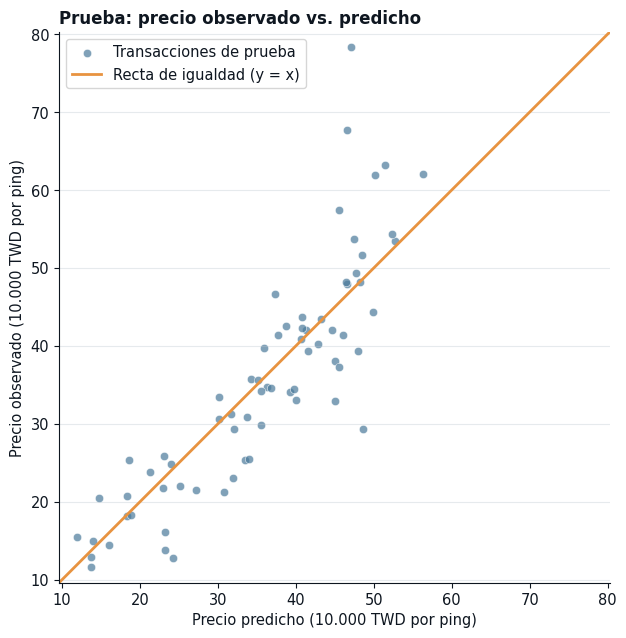

In [12]:
# C8 · Evaluación final (prueba se abre AQUÍ, después de registrar `seleccion` en C7)

# --- 1) Cargar prueba y verificar independencia respecto de desarrollo ---
prueba = pd.read_csv(RUTA_DATOS / "prueba.csv")
assert set(prueba["id_operacion"]).isdisjoint(set(desarrollo["id_operacion"])), "IDs compartidos"
assert set(prueba["grupo_ubicacion"]).isdisjoint(set(desarrollo["grupo_ubicacion"])), "Grupos compartidos"
print(f"Prueba: {prueba.shape[0]} filas | sin IDs ni grupos en común con desarrollo")

y_dev, y_prueba = desarrollo[OBJETIVO], prueba[OBJETIVO]

# --- 2) Reajustar con TODO desarrollo (el escalador aprende ahí) ---
rep_elegida, est_elegido = candidatos[seleccion["id"]]
modelo_final = crear_modelo(clone(est_elegido))
modelo_final.fit(representar(desarrollo, rep_elegida), y_dev)

lineal_ref = crear_modelo(LinearRegression())
lineal_ref.fit(representar(desarrollo, "original"), y_dev)

mediana_ref = DummyRegressor(strategy="median")
mediana_ref.fit(representar(desarrollo, "original"), y_dev)

# --- 3) Predecir en prueba ---
pred_final   = modelo_final.predict(representar(prueba, rep_elegida))
pred_lineal  = lineal_ref.predict(representar(prueba, "original"))
pred_mediana = mediana_ref.predict(representar(prueba, "original"))

# --- 4) Tabla de MAE y RMSE (en 10.000 TWD por ping) ---
def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred))}

tabla_prueba = pd.DataFrame({
    "Mediana (referencia)":          metricas(y_prueba, pred_mediana),
    "Lineal (referencia)":           metricas(y_prueba, pred_lineal),
    f"Elegido ({seleccion['id']})":  metricas(y_prueba, pred_final),
}).T.round(4)
display(tabla_prueba)

# --- 5) Predicciones y residuos del elegido (residuo = observado − predicho) ---
resultados = prueba[["id_operacion"]].copy()
resultados["observado"] = y_prueba.to_numpy()
resultados["predicho"]  = pred_final
resultados["residuo"]   = resultados["observado"] - resultados["predicho"]
print("Residuo medio:", round(resultados["residuo"].mean(), 4))

# --- 6) Figura observado vs. predicho (misma escala en ambos ejes) ---
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(resultados["predicho"], resultados["observado"], color=AZUL, alpha=0.7,
           edgecolor="white", linewidth=0.5, label="Transacciones de prueba")
lo = min(resultados["predicho"].min(), resultados["observado"].min()) - 2
hi = max(resultados["predicho"].max(), resultados["observado"].max()) + 2
ax.plot([lo, hi], [lo, hi], color=AMBAR, lw=2, label="Recta de igualdad (y = x)")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_title("Prueba: precio observado vs. predicho")
ax.set_xlabel("Precio predicho (10.000 TWD por ping)")
ax.set_ylabel("Precio observado (10.000 TWD por ping)")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación:** El modelo elegido tiene el menor error en la prueba: MAE de 5,04 y RMSE de 7,34, contra 6,05 y 8,37 de la lineal y 12,11 y 14,97 de la mediana. O sea que la ventaja que se vio en validación se mantiene (en validación fueron 5,61, 6,85 y 10,54). Mejora a la lineal en aproximadamente un punto de MAE, y a la mediana en más de la mitad. El RMSE es mayor que el MAE, señal de que hay algunos errores grandes, y el gráfico lo muestra: la mayoría de los puntos queda cerca de la recta, pero algunos precios altos se alejan. El residuo medio cercano a cero indica que el modelo no se equivoca sistemáticamente para un solo lado. Hay que tomar el resultado con cuidado, porque la prueba tiene solo 70 transacciones y el MAE de prueba es incluso menor que el de validación, algo que puede deberse a la muestra.

## 8.2 Consigna C9 — Examinar lo que oculta el promedio

1. Mostrar las dos transacciones con mayor error absoluto del candidato: ID, antigüedad, distancia, precio observado, predicción y residuo. Si hay empate en error absoluto, ordenar por ID ascendente. Explicar el signo del residuo y proponer una hipótesis prudente para cada caso, sin inventar atributos ausentes.
2. Comparar cantidad de transacciones y MAE del candidato entre distancia **hasta 1.000 m inclusive** y **más de 1.000 m**. El corte se fija antes de ver prueba. Si un grupo tiene pocos casos, señalar el límite.
3. Explicar en hasta seis líneas por qué estos errores no prueban un efecto causal de la distancia o la antigüedad y qué información adicional podría ser útil.

Esta sección diagnostica el modelo ya elegido. No habilita otra búsqueda.

In [13]:
# C9 · Diagnóstico del modelo ya elegido (no se prueba nada nuevo)

# Tabla de diagnóstico: variables de interés + resultados de C8
diag = prueba[["id_operacion", "antiguedad_anios", "distancia_mrt_m"]].copy()
diag["observado"] = y_prueba.to_numpy()
diag["predicho"]  = pred_final
diag["residuo"]   = diag["observado"] - diag["predicho"]      # observado − predicho
diag["error_abs"] = diag["residuo"].abs()

# --- 1) Las dos transacciones con mayor error absoluto (empate → ID ascendente) ---
top2 = (diag.sort_values(["error_abs", "id_operacion"], ascending=[False, True])
            .head(2)[["id_operacion", "antiguedad_anios", "distancia_mrt_m",
                      "observado", "predicho", "residuo"]]
            .round(2))
display(top2)

# --- 2) Error por grupo de distancia (corte fijado de antemano: 1.000 m) ---
diag["grupo_distancia"] = np.where(diag["distancia_mrt_m"] <= 1000,
                                   "Hasta 1.000 m (inclusive)", "Más de 1.000 m")
por_grupo = (diag.groupby("grupo_distancia")
                 .agg(transacciones=("error_abs", "size"),
                      MAE=("error_abs", "mean"),
                      precio_observado_medio=("observado", "mean"))
                 .round(2))
display(por_grupo)

,id_operacion,antiguedad_anios,distancia_mrt_m,observado,predicho,residuo
40,221,37.2,186.51,78.3,47.02,31.28
67,390,40.9,122.36,67.7,46.50,21.20


,transacciones,MAE,precio_observado_medio
grupo_distancia,,,
Hasta 1.000 m (inclusive),43,5.80,43.48
Más de 1.000 m,27,3.83,22.45


**Los dos mayores errores:** Son las transacciones 221 y 390: las dos son inmuebles bastante viejos (37 y 41 años) y muy cerca del MRT (187 m y 122 m), y en las dos el precio observado (78,3 y 67,7) es mucho más alto que el predicho (cerca de 47). El residuo es positivo, o sea que el modelo subestimó el precio. Una hipótesis prudente es que esos inmuebles tengan alguna característica que el dataset no recoge y que los hace valer más; por ejemplo, que se vendieran en condiciones especiales o que la superficie o la ubicación exacta sea distinta de lo que sugieren las seis variables. Con los datos disponibles no se puede saber cuál es la causa, así que queda solo como hipótesis.

**Por distancia:** El MAE es mayor en los inmuebles hasta 1.000 m (5,80 con 43 casos) que en los de más de 1.000 m (3,83 con 27 casos). Los dos peores errores están en el grupo cercano, y ese grupo también tiene precios más altos y más dispersos (media de 43,5 contra 22,4), así que es lógico que los errores sean más grandes en términos absolutos. Con 27 casos en el grupo lejano el MAE es poco preciso, y la diferencia entre grupos podría cambiar con otra muestra.

**Por qué esto no prueba un efecto causal:** Que el error o el precio cambie con la distancia o la antigüedad muestra una asociación en estos datos, no que esas variables causen el precio. Pueden influir cosas que no se observan, como la superficie, el estado del inmueble, el piso o la calidad de la construcción. Para acercarse a un efecto causal haría falta información adicional de ese tipo, o un diseño que compare inmuebles parecidos que solo difieran en la distancia.

# 9. Responder la pregunta y entregar
## 9.1 Consigna C10 — Síntesis y reproducibilidad

Redactar **200–300 palabras** que respondan la pregunta central. Incluir: método elegido y representación; MAE de validación y prueba frente a referencias; una conclusión del EDA conectada con el resultado; un error o grupo relevante; dos límites y una mejora futura que requeriría nueva evaluación.

No afirmar que el modelo determina el precio justo ni que sus coeficientes son efectos causales. Distinguir mejora predictiva observada, estabilidad entre pliegues y generalización a otro mercado.

Antes de entregar:

- Reiniciar el kernel y ejecutar todas las celdas en orden; resolver errores y guardar las salidas.
- Confirmar que la elección se registra antes de la carga de prueba y que ningún ajuste usa prueba.
- Completar interpretaciones y fuentes consultadas; conservar los datos sin modificaciones.
- Verificar que el notebook funciona junto a su carpeta `datasets/`, sin rutas personales.

Registrar aquí fuentes y apoyos consultados: material de la cátedra (U2, U3 y U4); documentación de scikit-learn sobre validación cruzada y prevención de filtraciones de información; ficha del dataset de UCI (Yeh, 2018)

**Síntesis final (200–300 palabras):**

Las alternativas con transformaciones y Ridge mejoraron la estimación frente a la regresión lineal original, dentro de este mercado. El método elegido por validación cruzada fue Ridge con alpha=10, con la distancia en logaritmo y la antigüedad al cuadrado (`ridge_curva_10`). Su MAE de validación fue 5,61 (en 10.000 TWD por ping), contra 6,85 de la lineal y 10,54 de la mediana. En la prueba, con 70 transacciones, dio 5,04, contra 6,05 de la lineal y 12,11 de la mediana, así que la ventaja se mantuvo.

El EDA ya mostraba curvatura: el precio caía rápido cerca del MRT y después se aplanaba, y la antigüedad tenía forma de curva. Eso es coherente con que la mayor mejora apareciera al pasar a la distancia en logaritmo. Entre los cuatro Ridge la diferencia fue mínima (cerca de 0,03) frente al desvío entre pliegues (cerca de 0,7), así que la mejora es estable frente a la lineal pero no puedo atribuirla solo a Ridge ni al término cuadrático, porque cambian representación y regularización a la vez.

Un error relevante fue el de las transacciones 221 y 390: inmuebles viejos y muy cerca del MRT, con precios mucho mayores que los predichos. Además, el MAE fue mayor hasta 1.000 m (5,80) que a más distancia (3,83).

Dos límites: la prueba es chica y las ubicaciones cercanas pueden seguir relacionadas entre pliegues; y faltan datos como la superficie o el estado del inmueble. Los resultados no se pueden generalizar a otra ciudad ni a otro período, y el modelo no determina un precio justo ni sus coeficientes son efectos causales. Una mejora futura sería validar por bloques geográficos o temporales, lo que requeriría una nueva evaluación.

## 9.2 Comprobación del entorno

Esta celda registra versiones y la existencia del paquete de datos. No evalúa por sí sola si las respuestas o modelos son correctos; comprobar también la lista de C10.

In [14]:
display(pd.Series({paquete: version(paquete)
                   for paquete in ["numpy", "pandas", "matplotlib", "scikit-learn"]}, name="version").to_frame())
assert (RUTA_DATOS / "desarrollo.csv").is_file()
assert (RUTA_DATOS / "prueba.csv").is_file()
print("Archivos locales disponibles. Revisar también respuestas, orden de evaluación y salidas.")

,version
numpy,2.4.6
pandas,2.2.3
matplotlib,3.10.0
scikit-learn,1.6.1


Archivos locales disponibles. Revisar también respuestas, orden de evaluación y salidas.


**Interpretación.** Las versiones permiten reproducir el entorno. La ejecución completa y las respuestas de las diez consignas constituyen la entrega; este control sólo comprueba dependencias y presencia de archivos.

# Referencias y licencia

- Yeh, I. (2018). *Real Estate Valuation* [dataset]. UCI Machine Learning Repository. [Ficha y diccionario](https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set). DOI: [10.24432/C5J30W](https://doi.org/10.24432/C5J30W). Datos distribuidos con [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); la cátedra renombró campos y agregó particiones.
- Scikit-learn developers. [Validación cruzada](https://scikit-learn.org/stable/modules/cross_validation.html) y [prevención de filtraciones de información](https://scikit-learn.org/stable/common_pitfalls.html). Consulta técnica opcional para resolver la comparación.
- Material de la cátedra: U2 (EDA), U3 (regresión lineal, polinómica y regularización) y U4 (validación y evaluación).

Fuentes consultadas por la cátedra el 18/09/2026. La trazabilidad de los archivos se detalla en `FUENTES_Y_LICENCIAS.md`.